# 04 - Model Training and Evaluation

**Owners:** Vinitha Palani (training) and Balaram Sahu (evaluation and tuning)

Workflow: benchmark -> compare candidate models with cross-validation -> tune the best one -> pick the
decision threshold from cost -> evaluate once on the held-out test split -> check fairness ->
train the final model as a SageMaker Training job.

Model comparison and tuning use a stratified sample of the 80% training split to keep them fast;
the final model is fitted on the full training split. The test split is used once, at the end.

In [1]:
import sys, json
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)

from src import config, data_utils, features, modeling

sns.set_theme(style="whitegrid")
FIG_DIR = "../docs/figures"

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()

In [2]:
train_df = data_utils.load_processed("train")
test_df = data_utils.load_processed("test")
X_train, y_train = train_df[features.MODEL_FEATURES], train_df["churn"].astype(int)
X_test, y_test = test_df[features.MODEL_FEATURES], test_df["churn"].astype(int)

# Stratified sample of the training split for model selection and tuning
n = min(config.SELECTION_SAMPLE_ROWS, len(train_df))
sample = train_df if n >= len(train_df) else train_test_split(train_df, train_size=n, stratify=train_df["churn"], random_state=config.RANDOM_SEED)[0]
X_s, y_s = sample[features.MODEL_FEATURES], sample["churn"].astype(int)
print(f"train {len(train_df):,} | test {len(test_df):,} | selection sample {len(sample):,} | churn rate {y_train.mean():.2%}")

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


[10/19/26 07:52:14] INFO     Initializing a Ray instance                                               ]8;id=6179626;file:///opt/conda/lib/python3.12/site-packages/awswrangler/distributed/ray/_core.py\_core.py]8;;\:]8;id=6179627;file:///opt/conda/lib/python3.12/site-packages/awswrangler/distributed/ray/_core.py#202\202]8;;\

2026-10-19 07:52:15,847	WARNING services.py:2213 -- WARNING: The object store is using /tmp/ray instead of /dev/shm because /dev/shm has only 906993664 bytes available. This will harm performance! You may be able to free up space by deleting files in /dev/shm. If you are inside a Docker container, you can increase /dev/shm size by passing '--shm-size=2.16gb' to 'docker run' (or add it to the run_options list in a Ray cluster config). Make sure to set this to more than 30% of available RAM.
2026-10-19 07:52:18,026	INFO worker.py:2012 -- Started a local Ray instance.
/opt/conda/lib/python3.12/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


train 130,626 | test 32,657 | selection sample 100,000 | churn rate 98.69%


## 1. Benchmark models

The benchmark gives a floor to beat: a rule-based score (four risk rules) and a logistic regression with only two features.
They are scored on the training sample, so the test split stays untouched.

In [3]:
cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_SEED)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "f1": "f1"}

heuristic_auc = modeling.metrics(y_s, modeling.benchmark_heuristic(sample), 0.5)["roc_auc"]
bench_cv = cross_validate(modeling.benchmark_two_feature_model(), X_s, y_s, cv=cv, scoring=SCORING)
benchmark_rows = {
    "benchmark: rules": {"roc_auc": heuristic_auc},
    "benchmark: 2-feature logreg": {k: bench_cv[f"test_{k}"].mean() for k in SCORING},
}
pd.DataFrame(benchmark_rows).T.round(4)

,roc_auc,pr_auc,recall,f1
benchmark: rules,0.8409,NaN,NaN,NaN
benchmark: 2-feature logreg,0.8640,0.998,1.0,0.9934


## 2. Compare candidate models (5-fold cross-validation)

In [4]:
results = {}
for name in ["logreg", "rf", "gb"]:
    scores = cross_validate(modeling.build_model(name), X_s, y_s, cv=cv, scoring=SCORING, n_jobs=-1)
    results[name] = {k: scores[f"test_{k}"].mean() for k in SCORING}
cv_table = pd.DataFrame(results).T.round(4)
cv_table

,roc_auc,pr_auc,recall,f1
logreg,0.9629,0.9995,0.8784,0.9350
rf,0.9958,0.9999,0.9924,0.9948
gb,0.9970,1.0000,0.9989,0.9973


In [5]:
best_type = cv_table["roc_auc"].idxmax()
print("best model type by cross-validated ROC-AUC:", best_type)

best model type by cross-validated ROC-AUC: gb


## 3. Hyperparameter tuning of the best model

Randomized search with 3-fold cross-validation, optimizing ROC-AUC.

In [6]:
SEARCH_SPACES = {
    "gb": {"clf__learning_rate": loguniform(0.02, 0.3), "clf__max_depth": randint(3, 10),
           "clf__max_iter": randint(150, 500), "clf__min_samples_leaf": randint(20, 200),
           "clf__l2_regularization": loguniform(1e-3, 10)},
    "rf": {"clf__n_estimators": randint(100, 400), "clf__max_depth": randint(6, 24),
           "clf__min_samples_leaf": randint(2, 30)},
    "logreg": {"clf__C": loguniform(1e-2, 1e2)},
}
search = RandomizedSearchCV(modeling.build_model(best_type), SEARCH_SPACES[best_type], n_iter=15, cv=3,
                            scoring="roc_auc", n_jobs=-1, random_state=config.RANDOM_SEED, refit=False)
search.fit(X_s, y_s)
best_params = {k.replace("clf__", ""): (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}
print("best params:", best_params, "| cv roc_auc:", round(search.best_score_, 4))

best params: {'l2_regularization': 0.014618962793704957, 'learning_rate': 0.10486361783805702, 'max_depth': 4, 'max_iter': 337, 'min_samples_leaf': 34} | cv roc_auc: 0.9971


## 4. Decision threshold from business cost

Out-of-fold predictions are used, so the threshold is not chosen on data the model was fitted on.
`COST_FALSE_NEGATIVE` and `COST_FALSE_POSITIVE` in `src/config.py` are placeholders: replace them with the company's real numbers.

In [7]:
oof = cross_val_predict(modeling.build_model(best_type, **best_params), X_s, y_s, cv=cv, method="predict_proba")[:, 1]
threshold = modeling.best_threshold(y_s, oof)
print(f"cost-optimal threshold: {threshold}  (a missed churner costs {config.COST_FALSE_NEGATIVE}, a wasted offer {config.COST_FALSE_POSITIVE})")

cost-optimal threshold: 0.39  (a missed churner costs 100.0, a wasted offer 20.0)


## 5. Final evaluation on the held-out test split (used once)

The tuned model is fitted on the full training split and compared with the two benchmarks.

In [8]:
final_model = modeling.build_model(best_type, **best_params).fit(X_train, y_train)
proba = final_model.predict_proba(X_test)[:, 1]

two_feat = modeling.benchmark_two_feature_model().fit(X_train, y_train)
final_table = pd.DataFrame({
    "benchmark: rules": modeling.metrics(y_test, modeling.benchmark_heuristic(test_df), 0.5),
    "benchmark: 2-feature logreg": modeling.metrics(y_test, two_feat.predict_proba(X_test)[:, 1], 0.5),
    f"final: {best_type}": modeling.metrics(y_test, proba, threshold),
}).T
final_table[["roc_auc", "pr_auc", "precision", "recall", "f1", "top_decile_precision", "expected_cost"]].round(4)

,roc_auc,pr_auc,precision,recall,f1,top_decile_precision,expected_cost
benchmark: rules,0.8501,0.9964,0.9991,0.5329,0.6950,1.0,1505920.0
benchmark: 2-feature logreg,0.8691,0.9980,0.9869,1.0000,0.9934,1.0,8540.0
final: gb,0.9978,1.0000,0.9961,1.0000,0.9980,1.0,2640.0


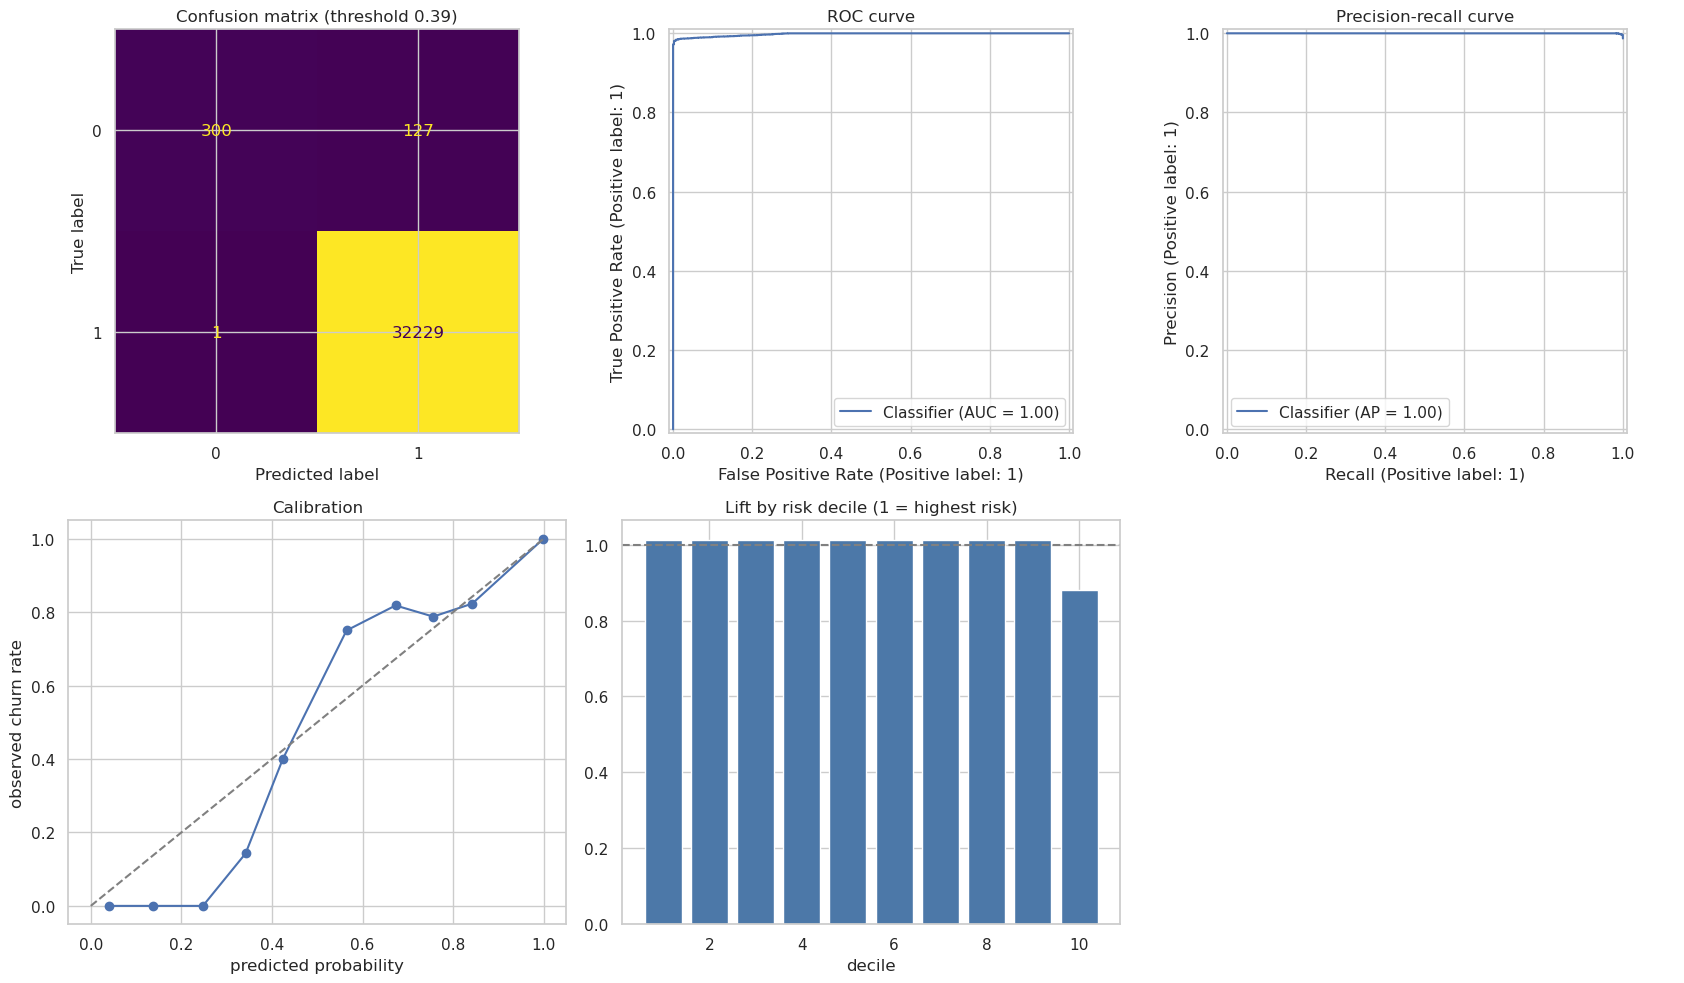

In [9]:
pred = (proba >= threshold).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[0, 0], colorbar=False)
axes[0, 0].set_title(f"Confusion matrix (threshold {threshold})")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0, 1]); axes[0, 1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[0, 2]); axes[0, 2].set_title("Precision-recall curve")
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10)
axes[1, 0].plot(mean_pred, frac_pos, marker="o"); axes[1, 0].plot([0, 1], [0, 1], "--", c="gray")
axes[1, 0].set_title("Calibration"); axes[1, 0].set_xlabel("predicted probability"); axes[1, 0].set_ylabel("observed churn rate")
lift = modeling.lift_table(y_test, proba)
axes[1, 1].bar(lift.index, lift["lift"], color="#4c78a8"); axes[1, 1].axhline(1, ls="--", c="gray")
axes[1, 1].set_title("Lift by risk decile (1 = highest risk)"); axes[1, 1].set_xlabel("decile")
axes[1, 2].axis("off")
savefig("model_evaluation")

## 6. Feature importance (permutation importance on the test split)

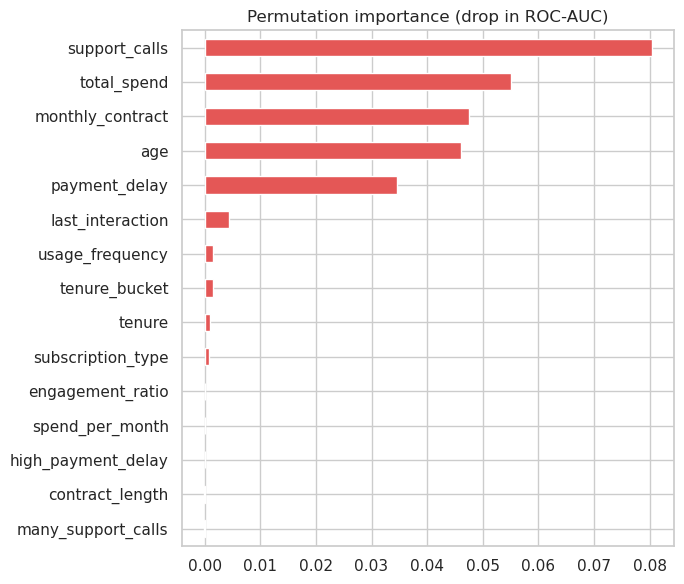

support_calls        0.0803
total_spend          0.0551
monthly_contract     0.0475
age                  0.0461
payment_delay        0.0345
last_interaction     0.0044
usage_frequency      0.0015
tenure_bucket        0.0014
tenure               0.0010
subscription_type    0.0007
dtype: float64

In [10]:
idx = np.random.RandomState(config.RANDOM_SEED).choice(len(X_test), size=min(20000, len(X_test)), replace=False)
imp = permutation_importance(final_model, X_test.iloc[idx], y_test.iloc[idx], scoring="roc_auc", n_repeats=3,
                             random_state=config.RANDOM_SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=features.MODEL_FEATURES).sort_values()
importance.tail(15).plot(kind="barh", figsize=(7, 6), color="#e45756")
plt.title("Permutation importance (drop in ROC-AUC)")
savefig("feature_importance")
importance.sort_values(ascending=False).head(10).round(4)

## 7. Fairness audit

Gender is not a model feature; Age is. Selection rate, recall, and false-positive rate are compared across gender
and age bands. Gaps above `MAX_FAIRNESS_GAP` are flagged and block promotion in the CI/CD pipeline.

In [11]:
audit = modeling.add_age_band(test_df)
for col in ["gender", "age_band"]:
    table = modeling.fairness_table(audit, pred, col)
    gap = modeling.max_fairness_gap(table)
    print(f"\n{col}: max gap {gap:.3f} -> {'REVIEW' if gap > config.MAX_FAIRNESS_GAP else 'ok'}")
    print(table.round(3))


gender: max gap 0.429 -> REVIEW
            n  selection_rate  recall  false_positive_rate
group                                                     
Female  16665           0.991     1.0                0.020
Male    15992           0.990     1.0                0.449

age_band: max gap 0.251 -> REVIEW
           n  selection_rate  recall  false_positive_rate
group                                                    
18-29   8119           0.991     1.0                0.296
30-49  13411           0.984     1.0                0.288
50-65  11127           0.999     1.0                0.538


## 8. Train the final model as a SageMaker Training job

Uses the same tuned settings and the entry script `scripts/train.py` (5-fold out-of-fold threshold, full fit, `model.joblib`).
Tuned settings are also saved to S3 so the CI/CD pipeline can reuse them.

In [22]:
import os
import shutil
import tempfile

import boto3
import joblib as training_joblib
import scipy
import sklearn
from sagemaker.core import image_uris
from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.train import ModelTrainer
from sagemaker.train.configs import Compute, InputData, OutputDataConfig, SourceCode

FRAMEWORK_VERSION = "1.4-2-py312"
INSTANCE_TYPE = "ml.m5.xlarge"
REPO_ROOT = os.path.abspath("..")

def stage_source():
    build_dir = tempfile.mkdtemp(prefix="churn-training-")
    shutil.copytree(
        os.path.join(REPO_ROOT, "src"),
        os.path.join(build_dir, "src"),
        ignore=shutil.ignore_patterns("__pycache__"),
    )
    for filename in os.listdir(os.path.join(REPO_ROOT, "scripts")):
        if filename.endswith(".py"):
            shutil.copy(os.path.join(REPO_ROOT, "scripts", filename), build_dir)
    with open(os.path.join(build_dir, "requirements.txt"), "w") as requirements:
        requirements.write(
            "pyarrow\n"
            f"numpy=={np.__version__}\n"
            f"scipy=={scipy.__version__}\n"
            f"scikit-learn=={sklearn.__version__}\n"
            f"joblib=={training_joblib.__version__}\n"
        )
    return build_dir

session = Session()
role = get_execution_role()
region = session.boto_region_name
BUCKET = session.default_bucket()
s3 = boto3.client("s3", region_name=region)

hyperparameters = {"model-type": best_type, **{k.replace("_", "-"): v for k, v in best_params.items()}}
s3.put_object(Bucket=BUCKET, Key=f"{config.MODEL_PREFIX}/best_params.json",
              Body=json.dumps({"model_type": best_type, "hyperparameters": {k: v for k, v in hyperparameters.items() if k != "model-type"}}).encode())

training_image = image_uris.retrieve(
    framework="sklearn",
    region=region,
    version=FRAMEWORK_VERSION,
    py_version="py3",
    instance_type=INSTANCE_TYPE,
    image_scope="training",
)

trainer = ModelTrainer(
    training_image=training_image,
    source_code=SourceCode(
        source_dir=stage_source(),
        entry_script="train.py",
        requirements="requirements.txt",
    ),
    compute=Compute(instance_type=INSTANCE_TYPE, instance_count=1),
    output_data_config=OutputDataConfig(
        s3_output_path=f"s3://{BUCKET}/{config.MODEL_PREFIX}/jobs"
    ),
    hyperparameters=hyperparameters,
    role=role,
    sagemaker_session=session,
    base_job_name="churn-train",
)
processed = f"s3://{BUCKET}/{config.PROCESSED_PREFIX}"
trainer.train(
    input_data_config=[
        InputData(channel_name="train", data_source=f"{processed}/train/"),
        InputData(channel_name="test", data_source=f"{processed}/test/"),
    ]
)
training_job = trainer._latest_training_job
model_data = training_job.model_artifacts.s3_model_artifacts
print("model artifact:", model_data)

[10/19/26 08:48:51] INFO     StoppingCondition not provided. Using default:                         ]8;id=6181753;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=6181754;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#128\128]8;;\
                             max_runtime_in_seconds=3600 max_wait_time_in_seconds=None                             
                             max_pending_time_in_seconds=None                                                      

                    INFO     OutputDataConfig compression type not provided. Using default:         ]8;id=6181759;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=6181760;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#165\165]8;;\
                             GZIP                                                                                  

                    INFO     Training image URI:                                               ]8;id=6181765;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py\model_trainer.py]8;;\:]8;id=6181766;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py#558\558]8;;\
                             683313688378.dkr.ecr.us-east-1.amazonaws.com/sagemaker-scikit-lea                     
                             rn:1.4-2-py312-cpu-py3                                                                

[10/19/26 08:48:52] INFO     Creating training_job resource.                                     ]8;id=6181771;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=6181772;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31238\31238]8;;\

Output()

...

                    INFO     churn-train-20261019084851/algo-1-1792399774:                       ]8;id=6182533;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=6182534;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31584\31584]8;;\
                             test_threshold=0.3100                                                                 

                    INFO     churn-train-20261019084851/algo-1-1792399774:                       ]8;id=6182539;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=6182540;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31584\31584]8;;\
                             ++ echo 'Training Container Execution Completed'                                      

                    INFO     churn-train-20261019084851/algo-1-1792399774:                       ]8;id=6182545;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=6182546;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31584\31584]8;;\
                             Training Container Execution Completed                                                

[10/19/26 08:51:05] INFO     Final Resource Status: Completed                                    ]8;id=6182551;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=6182552;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#31590\31590]8;;\

model artifact: s3://sagemaker-us-east-1-025824828736/churn/models/jobs/churn-train-20261019084851/output/model.tar.gz


## 9. Evaluate the trained artifact and save the evaluation report

In [23]:
import os
import tarfile
import tempfile
from urllib.parse import urlparse

import joblib
from numpy.random import MT19937, PCG64, Philox, SFC64
import numpy.random._pickle as numpy_pickle

for bit_generator in (MT19937, PCG64, Philox, SFC64):
    numpy_pickle.BitGenerators.setdefault(
        bit_generator,
        bit_generator,
    )

workdir = tempfile.mkdtemp()
parsed_model_uri = urlparse(model_data)
model_archive = os.path.join(workdir, "model.tar.gz")

s3.download_file(
    parsed_model_uri.netloc,
    parsed_model_uri.path.lstrip("/"),
    model_archive,
)

with tarfile.open(model_archive) as archive:
    archive.extractall(workdir, filter="data")

bundle = joblib.load(
    os.path.join(workdir, "model.joblib")
)

In [24]:
%%html

<p><b>Shutting down your kernel for this notebook to release resources.</b></p>
<button class="sm-command-button" data-commandlinker-command="kernelmenu:shutdown" style="display:none;">Shutdown Kernel</button>
        
<script>
try {
    els = document.getElementsByClassName("sm-command-button");
    els[0].click();
}
catch(err) {
    // NoOp
}    
</script>


I0000 00:00:1792399892.234877    7283 chttp2_transport.cc:1182] ipv4:169.255.255.2:34651: Got goaway [2] err=UNAVAILABLE:GOAWAY received; Error code: 2; Debug Text: Cancelling all calls {grpc_status:14, http2_error:2, created_time:"2026-10-19T08:51:32.234865518+00:00"}
*** SIGTERM received at time=1792399894 on cpu 0 ***
PC: @     0x7f287d53e2d2  (unknown)  epoll_wait
[2026-10-19 08:51:34,715 E 7050 7050] logging.cc:474: *** SIGTERM received at time=1792399894 on cpu 0 ***
[2026-10-19 08:51:34,715 E 7050 7050] logging.cc:474: PC: @     0x7f287d53e2d2  (unknown)  epoll_wait
